# ✂️ 3. Partición y variable objetivo

Este capítulo fija **antes de cualquier análisis** qué días son de entrenamiento y cuáles de prueba. Desde aquí, toda decisión basada en estadísticas de los datos (EDA, umbrales, escalado, hiperparámetros) se calcula **solo con train**. El conjunto de prueba solo se vuelve a tocar en el capítulo 8, para la evaluación final.

Además se define la variable objetivo, su transformación y las métricas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from comun import estilo, cargar_panel, fechas_eje, INICIO, CORTE, FIN, AZUL, NARANJA, GRIS

estilo()
SEED = 42
panel = cargar_panel()
print(f"panel: {len(panel):,} filas, {panel['negocio'].nunique()} negocios, {panel['fecha'].min().date()} a {panel['fecha'].max().date()}")

panel: 37,828 filas, 452 negocios, 2026-07-01 a 2026-09-23


## 🧭 3.1 Horizonte de pronóstico

| Elemento | Decisión |
|---|---|
| Qué se pronostica | `venta_total` de cada negocio para el **día siguiente** (horizonte $h = 1$) |
| Cuándo | Al cierre del día $t-1$ se pronostica el día $t$ |
| Información disponible | Todo lo observado hasta $t-1$ (ventas por medio, días sin venta) + el calendario de $t$ (día de la semana, festivo), que se conoce de antemano |
| Información prohibida | Cualquier dato del mismo día $t$, en particular la venta por medio de pago de ese día, que suma exactamente el objetivo |

Se eligió $h = 1$ porque es el uso operativo más directo (planear el día siguiente) y porque, con solo 85 días de historia, horizontes más largos dejarían muy pocos datos para entrenar y validar.

## 📆 3.2 Partición cronológica

La regla es de **calendario**, no se eligió mirando resultados:

- **Prueba:** las **últimas 3 semanas completas** (3 al 23 sep, 21 días). Así cada día de la semana aparece exactamente 3 veces en la prueba.
- **Entrenamiento:** todo lo anterior (1 jul al 2 sep, 64 días).

No se barajan filas: todo el entrenamiento es anterior a toda la prueba.

In [2]:
panel["particion"] = np.where(panel["fecha"] <= CORTE, "train", "test")

resumen = panel.groupby("particion").agg(
    desde=("fecha", "min"), hasta=("fecha", "max"), dias=("fecha", "nunique"),
    filas=("fecha", "size"), negocios=("negocio", "nunique")).loc[["train", "test"]]
resumen["desde"] = resumen["desde"].dt.date
resumen["hasta"] = resumen["hasta"].dt.date
resumen["% filas"] = (resumen["filas"] / resumen["filas"].sum() * 100).round(1)
resumen

,desde,hasta,dias,filas,negocios,% filas
particion,,,,,,
train,2026-07-01,2026-09-02,64,28469,448,75.30
test,2026-09-03,2026-09-23,21,9359,448,24.70


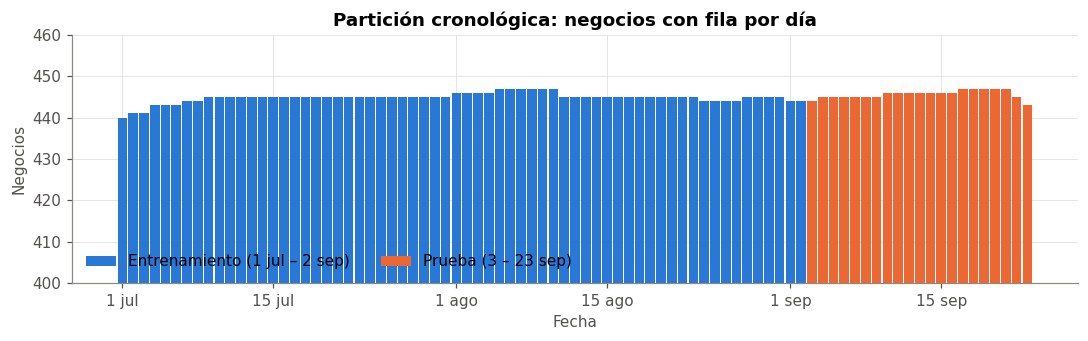

In [3]:
# línea de tiempo de la partición (solo cuento filas, no miro ventas de test)
filas_dia = panel.groupby(["fecha", "particion"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(filas_dia.index, filas_dia.get("train", 0), color=AZUL, width=0.9, label="Entrenamiento (1 jul – 2 sep)")
ax.bar(filas_dia.index, filas_dia.get("test", 0), color=NARANJA, width=0.9, label="Prueba (3 – 23 sep)")
ax.set_ylim(400, 460)
ax.set_title("Partición cronológica: negocios con fila por día")
ax.set_ylabel("Negocios")
ax.set_xlabel("Fecha")
fechas_eje(ax, filas_dia.index)
ax.legend(loc="lower left", frameon=False, ncol=2)
plt.tight_layout()
plt.show()

### Negocios en cada partición

El panel es desbalanceado, así que reviso qué negocios quedan en cada lado del corte.

In [4]:
# [IA] clasifico negocios según en qué partición tienen filas
pres = panel.groupby("negocio")["particion"].agg(lambda s: " + ".join(sorted(set(s), reverse=True)))
dias_train = panel[panel["particion"] == "train"].groupby("negocio").size()
tabla = pres.value_counts().rename("negocios").to_frame()
print(tabla.to_string())

solo_test = pres[pres == "test"].index
print("\nnegocios que solo están en test (entraron en septiembre):", len(solo_test))
nuevos_train = dias_train[dias_train < 14]
print("negocios con menos de 14 días en train:", len(nuevos_train))

              negocios
particion             
train + test       444
train                4
test                 4

negocios que solo están en test (entraron en septiembre): 4
negocios con menos de 14 días en train: 1


### Interpretación

- Casi todos los negocios tienen historia en train y en test, que es lo que se necesita para pronosticar con rezagos.
- Algunos negocios salen antes de septiembre (entregados en franquicia) y solo aportan a train.
- Unos pocos **entran en septiembre** y solo existen en test. Para ellos no hay historia con la cual pronosticar el primer día.

```{note}
**Decisión:** una fila solo se puede pronosticar si el negocio tiene la historia mínima que piden las variables del modelo (los rezagos más largos, que se fijan en los capítulos 6 y 7). Las filas sin esa historia se excluyen **tanto de train como de test** con la misma regla. En la práctica, un negocio nuevo necesitaría un modelo de arranque en frío, que queda fuera del alcance de este entregable.
```

## 🎯 3.3 Variable objetivo (solo train)

El objetivo es `venta_total` (COP por negocio y día). Desde aquí **todo se calcula solo con train**.

In [5]:
train = panel[panel["particion"] == "train"].copy()
y = train["venta_total"]

def forma_de(v):
    return [v.mean(), v.median(), v.std(), stats.skew(v), stats.kurtosis(v)]

z = np.log1p(y.clip(lower=0))
forma = pd.DataFrame({
    "escala original (COP)": forma_de(y),
    "log1p, todos": forma_de(z),
    "log1p, solo y > 0": forma_de(z[y > 0]),
}, index=["media", "mediana", "desv. estándar", "asimetría", "curtosis (exceso)"])
print(f"filas de train: {len(y):,}")
print(f"días con venta 0: {(y == 0).sum()} ({(y == 0).mean():.2%}); de ellos sin registro: {train.loc[y == 0, 'sin_registro'].sum()}")
print(f"días con venta negativa: {(y < 0).sum()}  |  venta < 100 mil COP: {(y.between(0, 1e5, inclusive='right')).mean():.1%}")
forma

filas de train: 28,469
días con venta 0: 156 (0.55%); de ellos sin registro: 156
días con venta negativa: 2  |  venta < 100 mil COP: 3.9%


,escala original (COP),"log1p, todos","log1p, solo y > 0"
media,"23,155,449.07",15.45,15.53
mediana,"5,439,790.00",15.51,15.52
desv. estándar,"36,559,386.92",2.34,2.04
asimetría,2.35,-1.84,-0.50
curtosis (exceso),6.27,9.11,-0.17


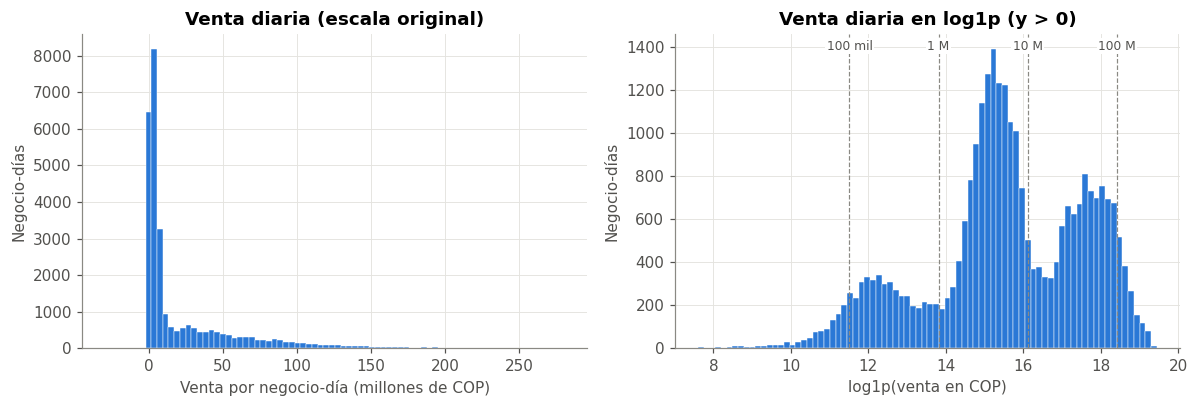

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.hist(y / 1e6, bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
ax.set_title("Venta diaria (escala original)")
ax.set_xlabel("Venta por negocio-día (millones de COP)")
ax.set_ylabel("Negocio-días")

ax = axes[1]
ax.hist(np.log1p(y[y > 0]), bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
ax.set_title("Venta diaria en log1p (y > 0)")
ax.set_xlabel("log1p(venta en COP)")
ax.set_ylabel("Negocio-días")
for v, et in [(np.log1p(1e5), "100 mil"), (np.log1p(1e6), "1 M"), (np.log1p(1e7), "10 M"), (np.log1p(1e8), "100 M")]:
    ax.axvline(v, color=GRIS, lw=0.8, ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.95, et, fontsize=8, ha="center", color="#52514e",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
plt.tight_layout()
plt.show()

### Interpretación

- En escala original la venta está **muy sesgada a la derecha**: la media es varias veces la mediana, porque unos pocos negocios grandes venden cientos de millones al día. Un modelo lineal ajustado en esa escala dedicaría casi todo su esfuerzo a los negocios grandes.
- En `log1p` y sin los ceros, la asimetría pasa de 2,35 a −0,50 y la curtosis queda cerca de la normal (ver tabla) y se ven los **grupos de tamaño** del capítulo 1 (alrededor de 100 mil, 5 M y 50 M COP/día).
- Si se incluyen los ceros, la asimetría en log vuelve a ser fuerte (negativa). Los 156 días sin venta (0,55 % de train, **todos** días sin registro) forman un pico aislado en 0, muy lejos del resto (~15 en log). Son pocos, pero en escala log generan errores enormes: por eso el modelo recibe `dias_sin_venta7` como variable, y en el capítulo 8 se revisa cuánto pesan en el error.
- Los negativos son solo 2 días (reversos).

```{note}
**Decisiones sobre el objetivo** (hallazgo → decisión):

| Hallazgo | Decisión |
|---|---|
| Asimetría fuerte y escala que cambia varios órdenes de magnitud entre negocios | Modelar en $\log(1 + y)$ y devolver las predicciones a COP con $e^{\hat z} - 1$ |
| `log1p` no admite los reversos negativos | Recortar el objetivo a 0 **solo al transformarlo para entrenar** (regla fija, no depende de los datos). La evaluación usa el valor real, incluidos los negativos |
| Días con venta 0 o muy pequeña | El MAPE se calcula solo con $y > 0$ y se acompaña de métricas estables (ver 3.4) |

La transformación va **dentro del Pipeline** (`TransformedTargetRegressor`, cap. 7), así que no hay un paso manual que se pueda aplicar mal en test.
```

## 📐 3.4 Métricas de evaluación

El enunciado pide RMSE, MAPE y R². Por lo que se vio arriba, se agregan métricas que no se desestabilizan con valores pequeños:

| Métrica | Escala | Por qué |
|---|---|---|
| **RMSE** | COP | Error típico en dinero. Lo dominan los negocios grandes |
| **RMSE log** | log1p | Error relativo promedio. Trata por igual a negocios grandes y pequeños. **Es la métrica que se optimiza** en la validación cruzada |
| **MAPE** | % (solo $y > 0$) | Pedida por el enunciado. **Se infla con los días de venta muy pequeña**: un día de 10 mil COP con pronóstico de 100 mil da un error del 900 % |
| **MdAPE** | % | Mediana del error porcentual: la versión robusta del MAPE |
| **WAPE** | % | $\sum|e| / \sum|y|$: error total relativo a la venta total. Es la más interpretable para el negocio |
| **R²** | COP y log | Pedido por el enunciado. **Ojo:** en un panel, gran parte del R² viene de la diferencia de tamaño entre negocios (ver cap. 8) |
| **R² intra-negocio** | log | R² después de restar a cada negocio su media: mide si el modelo captura las variaciones **día a día**, que es lo difícil |

Todas las métricas se comparan contra las **líneas base ingenuas** (persistencia e ingenuo estacional). Un modelo que no les gane no sirve, por alto que sea su R².

## ✅ Resumen del capítulo

| Aspecto | Decisión |
|---|---|
| Horizonte | $h = 1$ día |
| Train | 1 jul – 2 sep 2026 (64 días) |
| Test | 3 – 23 sep 2026 (21 días = 3 semanas completas) |
| Filas sin historia suficiente | Se excluyen de train y de test con la misma regla |
| Objetivo | `venta_total`, modelado como $\log(1 + \max(y, 0))$ dentro del Pipeline |
| Métrica de optimización | RMSE en escala log |
| Métricas reportadas | RMSE, RMSE log, MAPE, MdAPE, WAPE, R², R² log, R² intra-negocio |

```{warning}
**Limitaciones de la partición.** (1) El test solo tiene 3 semanas y **ningún festivo** (los 3 festivos del periodo están en train). (2) Con 64 días de train, la validación cruzada temporal tendrá pocos folds cortos (cap. 6 y 8). (3) El resultado en test describe septiembre de 2026, no el comportamiento de todo el año.
```